In [23]:
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

import threshold as th

In [24]:
df_train = pd.read_csv("../data/train.csv", index_col="ID")
df_test = pd.read_csv("../data/test.csv", index_col="ID")

X = df_train.drop(columns="Y")
y = df_train["Y"]

cat_cols = ["x4", "x5", "x10"]

display(df_train.head())
display(df_test.head())

,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,Y
ID,,,,,,,,,,,
1,0.0173,-1.0968,0.3725,0,2,0.0547,1.5471,-0.3371,-0.4551,1,0
2,-0.2145,0.5228,0.2572,0,0,0.0489,-1.9378,0.2004,-0.7517,2,0
3,-1.4413,0.1400,-0.1907,1,0,-2.2845,-0.0585,-0.0021,-0.5917,0,1
4,-0.5113,-0.5586,-0.4460,1,0,1.4341,0.7005,-2.6717,-0.7258,0,0
5,-0.8045,-0.7673,-1.2111,0,0,0.2241,-0.2277,-1.7400,-0.2095,3,0


,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10
ID,,,,,,,,,,
15001,-1.9425,0.9313,3.7991,0,0,0.8120,1.0790,-1.1039,-1.6808,3
15002,0.3013,-0.4149,-1.6684,1,1,-0.2060,-1.0022,1.6635,0.8439,3
15003,0.4617,1.1685,3.7372,0,0,-0.5036,-0.0696,-0.0044,0.6029,1
15004,-1.5574,1.9310,-0.0626,1,1,-0.0634,0.0315,-0.0472,-0.8563,0
15005,-2.1532,0.6695,0.7953,1,0,2.3339,-0.3477,0.2725,-1.7045,2


In [26]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint, uniform

both = pd.concat([X, df_test])
both = pd.get_dummies(both, columns=cat_cols, dtype="uint8")
both = both.astype("float32")

X_all = both.iloc[:len(X)]
test_all = both.iloc[len(X):]

params = {
    "min_samples_leaf": randint(5, 50),
    "max_depth": [10, 20, 30],
    "max_features": ["sqrt", 0.3, .5, .7],
}

search = RandomizedSearchCV(
    RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=0, class_weight="balanced"),
    params,
    n_iter=20,
    scoring="f1",
    cv=StratifiedKFold(3, shuffle=True, random_state=0),
    random_state=0,
    n_jobs=1,
    verbose=2,
)
search.fit(X_all, y)
print(search.best_params_, search.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
[CV] END .max_depth=10, max_features=0.7, min_samples_leaf=5; total time=   5.9s
[CV] END .max_depth=10, max_features=0.7, min_samples_leaf=5; total time=   6.8s
[CV] END .max_depth=10, max_features=0.7, min_samples_leaf=5; total time=   6.4s
[CV] END max_depth=20, max_features=0.7, min_samples_leaf=26; total time=   7.1s
[CV] END max_depth=20, max_features=0.7, min_samples_leaf=26; total time=   6.0s
[CV] END max_depth=20, max_features=0.7, min_samples_leaf=26; total time=   6.4s
[CV] END max_depth=30, max_features=sqrt, min_samples_leaf=28; total time=   5.3s
[CV] END max_depth=30, max_features=sqrt, min_samples_leaf=28; total time=   4.3s
[CV] END max_depth=30, max_features=sqrt, min_samples_leaf=28; total time=   5.3s
[CV] END max_depth=30, max_features=sqrt, min_samples_leaf=29; total time=   5.7s
[CV] END max_depth=30, max_features=sqrt, min_samples_leaf=29; total time=   7.9s
[CV] END max_depth=30, max_features=sqrt, m

In [27]:
model = RandomForestClassifier(
    n_estimators=500,
    min_samples_leaf=10,
    max_features=0.7,
    max_depth=10,
    class_weight="balanced",
    n_jobs=-1,
    random_state=0
)

print(cross_val_score(model, X_all, y, cv=5, scoring="f1").mean())

0.691884054978828


Best F1 score: 0.694
Best threshold: 0.520


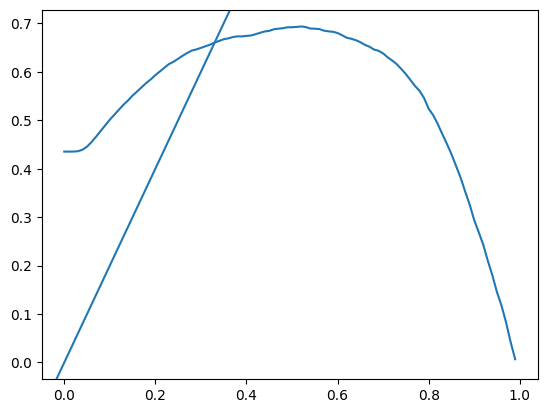

In [28]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt

probs = cross_val_predict(model, X_all, y, cv=5, method="predict_proba")[:, 1]

thresholds = np.arange(0.0, 1, 0.01)
f1s = [f1_score(y, probs >= t) for t in thresholds]

best_f1 = max(f1s)
best_threshold = thresholds[f1s.index(best_f1)]

print(f"Best F1 score: {best_f1:.3f}")
print(f"Best threshold: {best_threshold:.3f}")

plt.plot(thresholds, f1s)
plt.axline((0, 0), slope=2)
plt.show()

In [30]:
model.fit(X_all, y)

prediction_probs = pd.Series(
    model.predict_proba(test_all)[:, 1],
    index=df_test.index,
    name="probability"
)

display(prediction_probs.head())

submission = pd.DataFrame({
    "ID": df_test.index,
    "Y": (prediction_probs > best_threshold).astype(int)
})

submission_filepath = "./submissions/rf3.csv"
submission.to_csv(submission_filepath, index=False)

# get percent of positive predictions for best threshold
(prediction_probs > best_threshold).mean()

ID
15001    0.201886
15002    0.143802
15003    0.150861
15004    0.079795
15005    0.066068
Name: probability, dtype: float64

np.float64(0.3004)